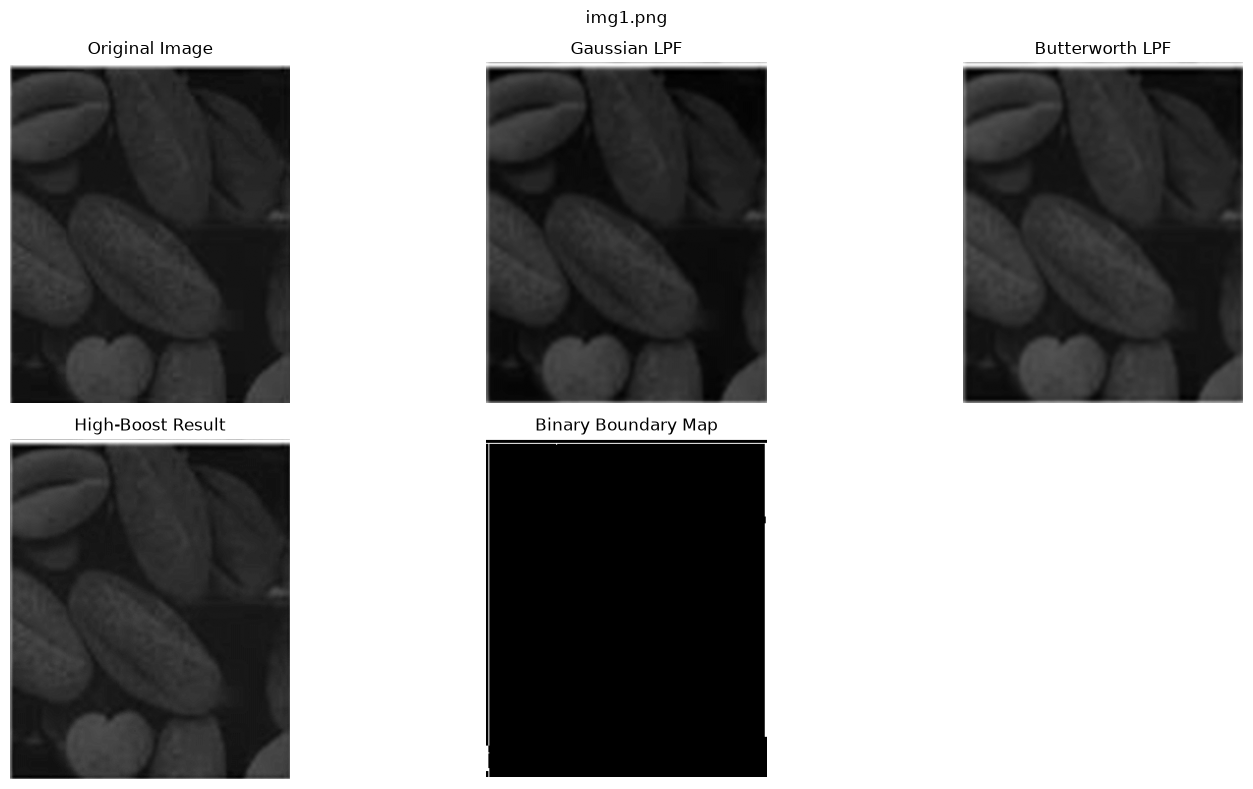

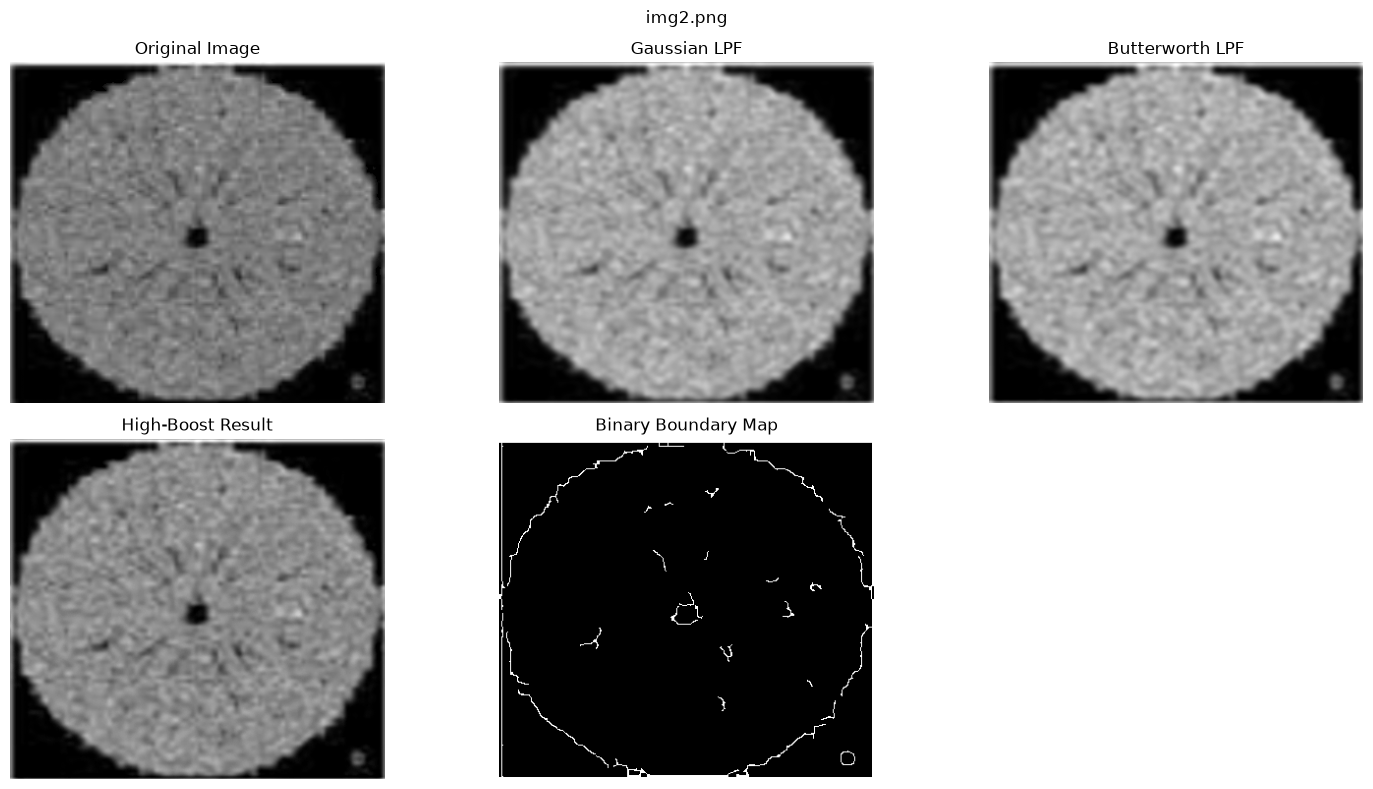

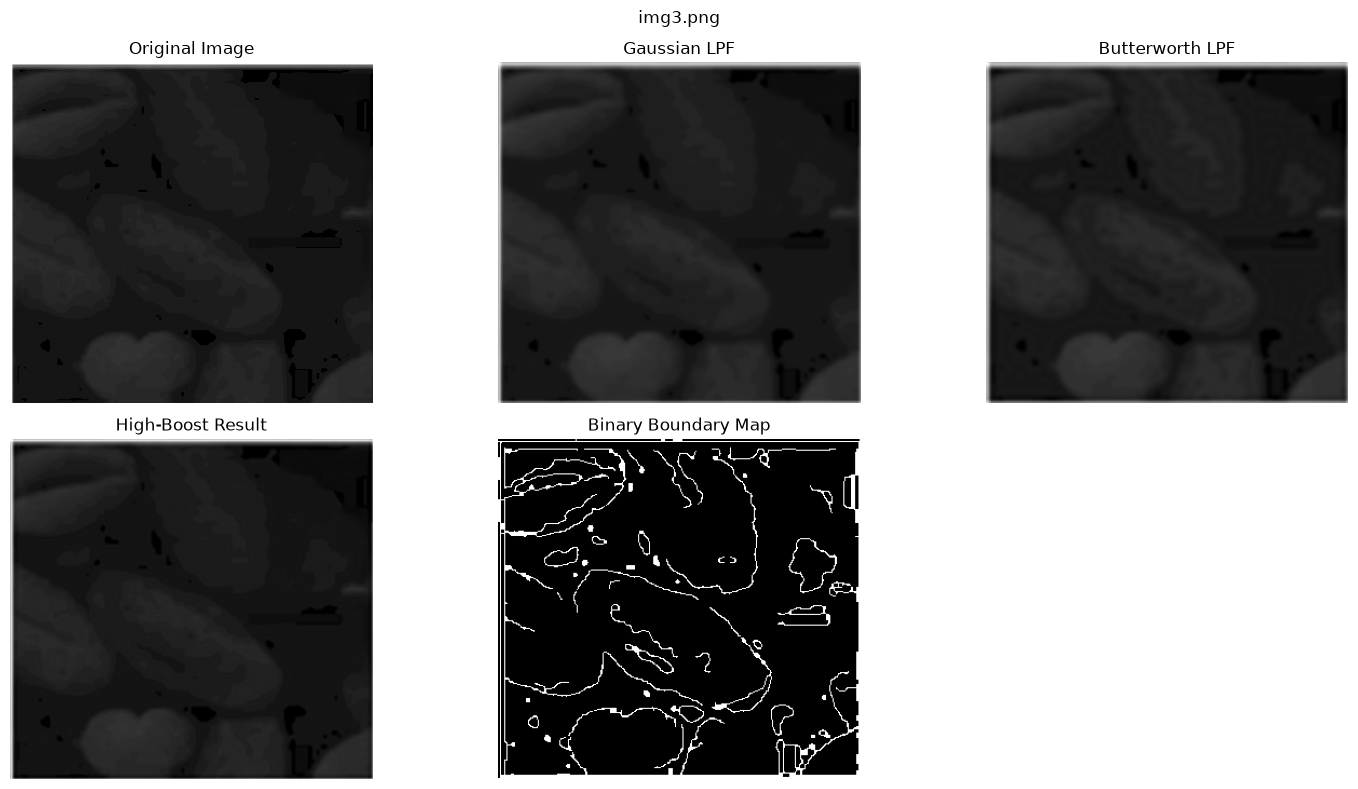

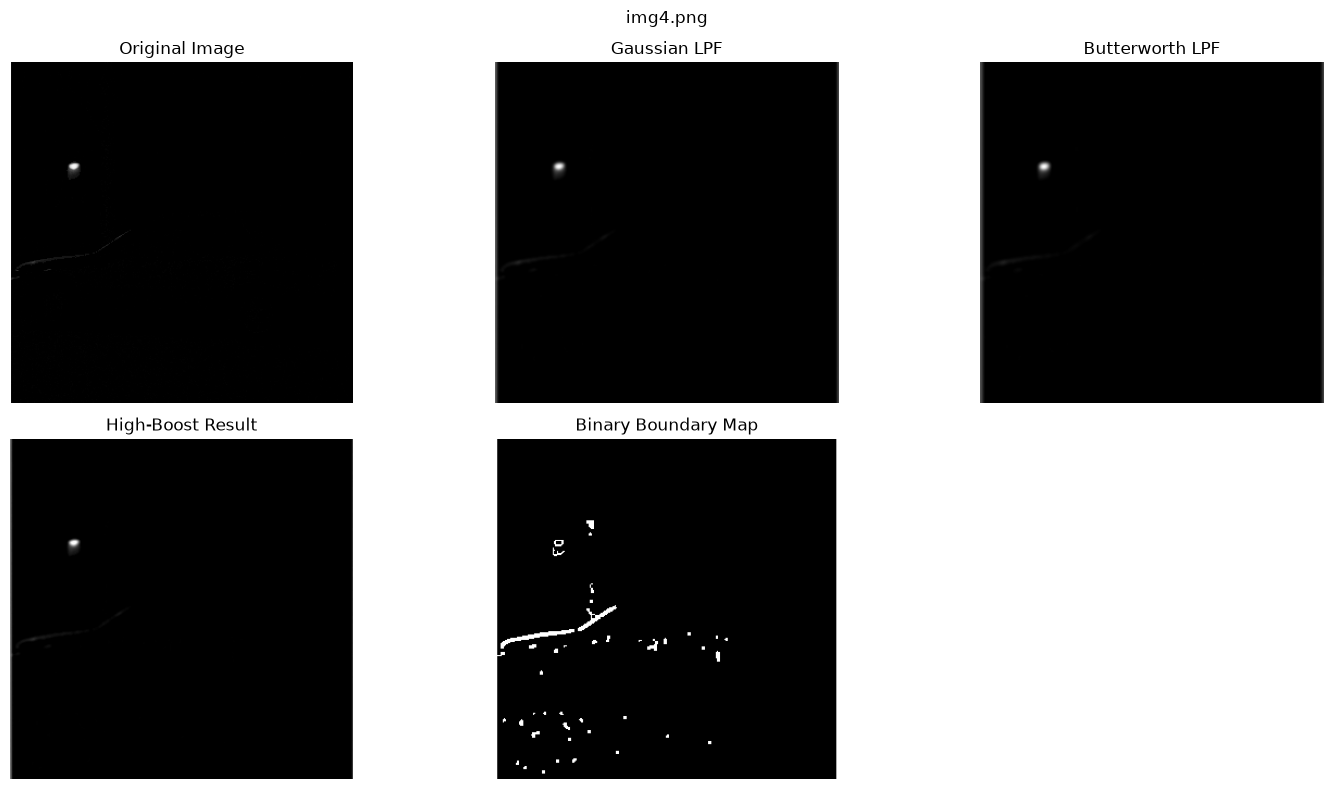

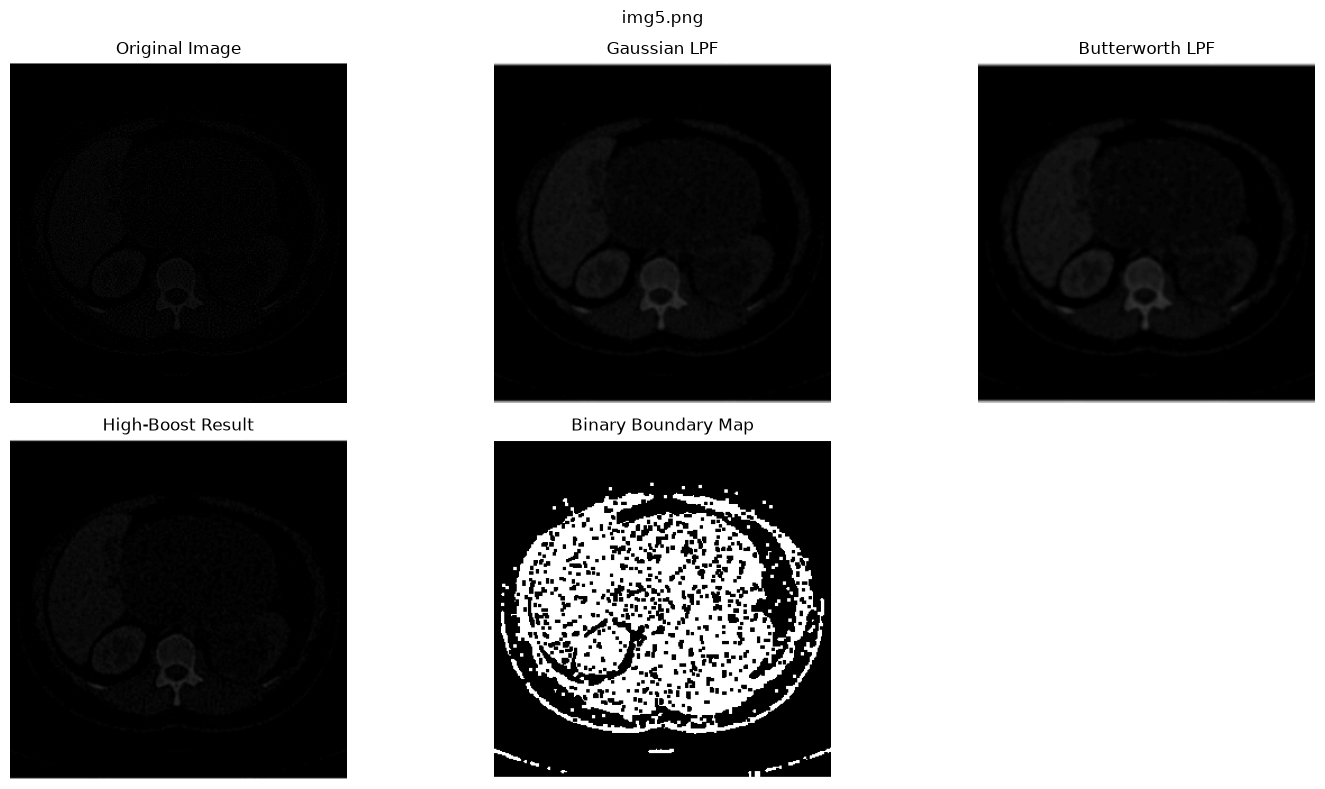

   Image  Laplacian Variance  Boundary Pixels  Boundary Percentage  Processing Time (seconds)
img1.png           75.964261             2099             2.128587                   0.106712
img2.png          118.546609             5366             4.070517                   0.173233
img3.png          236.891360             8936             8.442933                   0.081965
img4.png           94.138526             2287             2.312250                   0.125147
img5.png          114.138711            31882            35.073707                   0.144405


In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import time
import pandas as pd
input_folder = "OEP10"

# Function for frequency-domain filtering
def frequency_filter(image, filter_type="gaussian", cutoff=40, order=2):
    rows, cols = image.shape
    
    # Fourier Transform
    spectrum = np.fft.fft2(image)
    spectrum_shift = np.fft.fftshift(spectrum)

    # Calculate distance from the frequency centre
    x = np.arange(cols) - cols // 2
    y = np.arange(rows) - rows // 2
    X, Y = np.meshgrid(x, y)
    D = np.sqrt(X**2 + Y**2)

    # Generate frequency filter
    if filter_type == "gaussian":
        mask = np.exp(-(D**2) / (2 * cutoff**2))
    elif filter_type == "butterworth":
        mask = 1 / (1 + (D / cutoff)**(2 * order))

    # Apply filter
    filtered_spectrum = spectrum_shift * mask

    # Inverse Fourier Transform
    result = np.fft.ifft2(
        np.fft.ifftshift(filtered_spectrum)
    )
    result = np.real(result)
    return np.clip(result, 0, 255).astype(np.uint8)

# Function for frequency-domain high-boost enhancement
def high_boost(image, cutoff=40, alpha=1.5):
    rows, cols = image.shape
    spectrum = np.fft.fft2(image)
    spectrum_shift = np.fft.fftshift(spectrum)
    x = np.arange(cols) - cols // 2
    y = np.arange(rows) - rows // 2
    X, Y = np.meshgrid(x, y)
    D = np.sqrt(X**2 + Y**2)

    # Gaussian low-pass filter
    low_pass = np.exp(-(D**2) / (2 * cutoff**2))

    # High-boost filter
    boost_filter = 1 + alpha * (1 - low_pass)
    enhanced_spectrum = spectrum_shift * boost_filter
    result = np.fft.ifft2(
        np.fft.ifftshift(enhanced_spectrum)
    )
    result = np.real(result)
    return np.clip(result, 0, 255).astype(np.uint8)

# Get all images from the dataset folder
image_files = []
for extension in ["*.png"]:
    image_files.extend(
        glob.glob(os.path.join(input_folder, extension))
    )
results = []

# Process every image
for image_path in image_files:
    start_time = time.time()
    filename = os.path.basename(image_path)
    name = os.path.splitext(filename)[0]
    
    # Read image in grayscale
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    # Apply Gaussian low-pass filtering
    gaussian_result = frequency_filter(
        image, "gaussian", cutoff=40
    )

    # Apply Butterworth low-pass filtering
    butterworth_result = frequency_filter(
        image, "butterworth", cutoff=40, order=2
    )

    # Apply high-boost enhancement to the smoothed image
    enhanced_image = high_boost(
        gaussian_result, cutoff=40, alpha=1.5
    )

    # Automatic Canny thresholds
    median_value = np.median(enhanced_image)
    lower = int(max(0, 0.66 * median_value))
    upper = int(min(255, 1.33 * median_value))

    # Detect image boundaries
    edges = cv2.Canny(
        enhanced_image, lower, upper
    )

    # Connect small gaps in boundaries
    kernel = np.ones((3, 3), np.uint8)
    clean_edges = cv2.morphologyEx(
        edges, cv2.MORPH_CLOSE, kernel
    )

    # Calculate performance measurements
    laplacian_variance = cv2.Laplacian(
        enhanced_image, cv2.CV_64F
    ).var()
    edge_pixels = np.count_nonzero(clean_edges)
    edge_percentage = (
        edge_pixels / clean_edges.size
    ) * 100
    processing_time = time.time() - start_time

    # Store comparison values
    results.append({
        "Image": filename,
        "Laplacian Variance": laplacian_variance,
        "Boundary Pixels": edge_pixels,
        "Boundary Percentage": edge_percentage,
        "Processing Time (seconds)": processing_time
    })

    # Display results
    plt.figure(figsize=(15, 8))
    images = [
        image,
        gaussian_result,
        butterworth_result,
        enhanced_image,
        clean_edges
    ]
    titles = [
        "Original Image",
        "Gaussian LPF",
        "Butterworth LPF",
        "High-Boost Result",
        "Binary Boundary Map"
    ]
    for i in range(5):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i], cmap="gray")
        plt.title(titles[i])
        plt.axis("off")
    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()

# Generate comparison report
if results:
    report = pd.DataFrame(results)
    print(report.to_string(index=False))